In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_auc_score, RocCurveDisplay
)

In [3]:
df = pd.read_csv("house_price_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\\nPrice summary:")
print(df["Price"].describe())

Dataset shape: (15025, 18)


,House_ID,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location,Furnishing_Status,Parking_Available,Garage_Count,Lot_Size_sqft,Condition,Distance_to_City_Center_km,Crime_Rate_Index,School_Rating,Has_Pool,Renovated,Price
0,3975,1665.3,2.0,4.0,1.0,1988,Green field,Unfurnished,NO,3.0,4817.2,Excellent,4.23,51.48,6.36,No,no,309277
1,12325,2646.2,2.0,5.0,2.0,2005,riverside,NaN,no,3.0,6998.6,EXCELLENT,3.67,14.55,7.45,yes,Y,563512
2,7202,2791.2,4.0,3.0,3.0,2011,Lake side,Unfurnished,NO,0.0,3427.6,good,8.97,38.84,NaN,Yes,no,495806
3,8355,1594.1,2.0,3.0,1.0,1972,Hillview,semifurnished,no,3.0,5703.1,fair,1.54,38.31,1.60,no,Yes,240776
4,12742,3227.0,3.0,5.0,2.0,1995,NaN,Unfurnished,yes,3.0,7352.4,Good,5.06,30.50,4.72,no,yes,413975


\nPrice summary:
count     15025.000000
mean     369062.817038
std      127269.347523
min       20000.000000
25%      280791.000000
50%      359454.000000
75%      449125.000000
max      926035.000000
Name: Price, dtype: float64


In [4]:
price_threshold = df["Price"].median()

df["High_Price"] = (df["Price"] >= price_threshold).astype(int)

print("Median price threshold:", price_threshold)
print("\\nClass distribution:")
print(df["High_Price"].value_counts().sort_index())
print("\\nClass meaning: 0 = Below median, 1 = At or above median")

Median price threshold: 359454.0
\nClass distribution:
High_Price
0    7512
1    7513
Name: count, dtype: int64
\nClass meaning: 0 = Below median, 1 = At or above median


In [5]:
X = df.drop(columns=["House_ID", "Price", "High_Price"], errors="ignore")
y = df["High_Price"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Number of input features:", X.shape[1])
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Number of input features: 16
Numerical features: ['Area_sqft', 'Bedrooms', 'Bathrooms', 'Floors', 'Year_Built', 'Garage_Count', 'Lot_Size_sqft', 'Distance_to_City_Center_km', 'Crime_Rate_Index', 'School_Rating']
Categorical features: ['Location', 'Furnishing_Status', 'Parking_Available', 'Condition', 'Has_Pool', 'Renovated']


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 12020
Testing records: 3005


In [7]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [8]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [9]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Actual_Class": y_test.values,
    "Predicted_Class": y_pred,
    "Probability_High_Price": y_probability
})

display(results.head(10))

,Actual_Class,Predicted_Class,Probability_High_Price
0,0,0,0.059429
1,0,0,0.061254
2,0,0,0.001478
3,1,1,0.999993
4,0,0,0.233932
5,0,0,0.001845
6,0,0,0.067525
7,0,0,0.086799
8,1,1,0.837065
9,1,1,0.999973


In [10]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("\\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Below median", "At/above median"],
    zero_division=0
))
print("ROC-AUC:", round(roc_auc_score(y_test, y_probability), 4))

Accuracy: 0.9105
\nClassification Report:
                 precision    recall  f1-score   support

   Below median       0.91      0.91      0.91      1502
At/above median       0.91      0.91      0.91      1503

       accuracy                           0.91      3005
      macro avg       0.91      0.91      0.91      3005
   weighted avg       0.91      0.91      0.91      3005

ROC-AUC: 0.9722


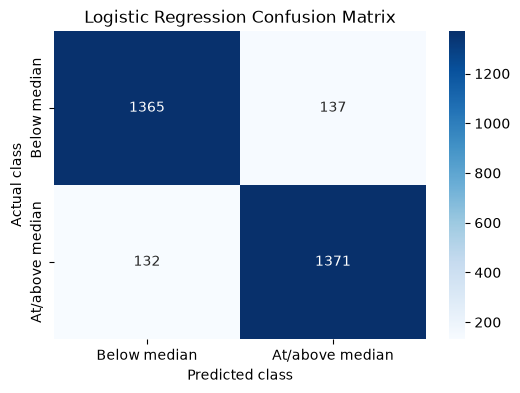

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Below median", "At/above median"],
    yticklabels=["Below median", "At/above median"]
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

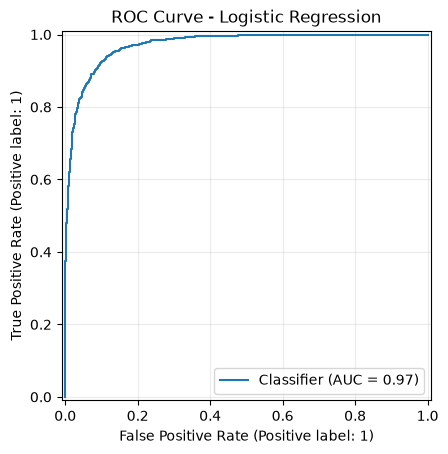

In [12]:
RocCurveDisplay.from_predictions(y_test, y_probability)
plt.title("ROC Curve - Logistic Regression")
plt.grid(alpha=0.25)
plt.show()

In [13]:
new_house = X.iloc[[0]].copy()

predicted_class = model.predict(new_house)[0]
probability = model.predict_proba(new_house)[0, 1]

print("Probability of high-price class:", round(probability, 4))
if predicted_class == 1:
    print("Prediction: At or above median price")
else:
    print("Prediction: Below median price")

Probability of high-price class: 0.0132
Prediction: Below median price
